# SEM attenuation · the nonlinear Q fit and the attenuating C-PML

Two pieces of SPECFEM2D's attenuation on the SEM's displacement and potential classes
(`ViscoElasticSEM2DDeformed`, `ViscoAcousticPotentialSEM2D`):

| | | |
|---|---|---|
| `fit="nonlinear"` | the relaxation frequencies fitted with the strengths, for each Q | SPECFEM2D's `USE_SOLVOPT` |
| the C-PML | the absorbing layer attenuates as the medium does | SPECFEM2D's visco-elastic C-PML |

A generalized standard linear solid of `n_sls` mechanisms has the modulus
`M(w) = M_R (1 + sum_l w_l i w tau_l / (1 + i w tau_l))`. The default fit keeps the relaxation
times `tau_l` log-spaced over the band and fits the strengths `w_l` by linear least squares;
the nonlinear fit moves the `tau_l` as well, per Q, and keeps both positive. The absorbing
layer used to run without attenuation, so the medium's modulus jumped at its edge by the
dispersion of the band; it now attenuates, with the memories on the C-PML's stretched strains.

See [Visco-elastic attenuation](../user-guide/sem.md#visco-elastic-attenuation).

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.special import hankel2

from sweep.equations.gsls_nonlinear import GSLSNonlinearFit
from sweep.equations.visco_elastic import GSLSFit, gsls_relaxation_times
from sweep.sem import ElasticSEM2DDeformed, PropSEM, ViscoElasticSEM2DDeformed

DEV = "cuda" if torch.cuda.is_available() else "cpu"   # the visco classes run on impl='eager'
F0 = 15.0                                  # source and reference frequency (Hz)
BAND = (F0 / 10.0, 10.0 * F0)              # SPECFEM2D's band
print(f"device {DEV}")

device cuda


## 1. The fit

Both fits minimise the same residual, `Q Im M(w) - Re M(w)`, at frequencies log-spaced over
the band: the linear fit at SPECFEM2D's `2 n_sls - 1` of them (or at 200), the nonlinear one at
its `4 n_sls`. Below, the error of the `Q(f)` each realises for a target Q: three mechanisms at
Q = 10 and Q = 3.

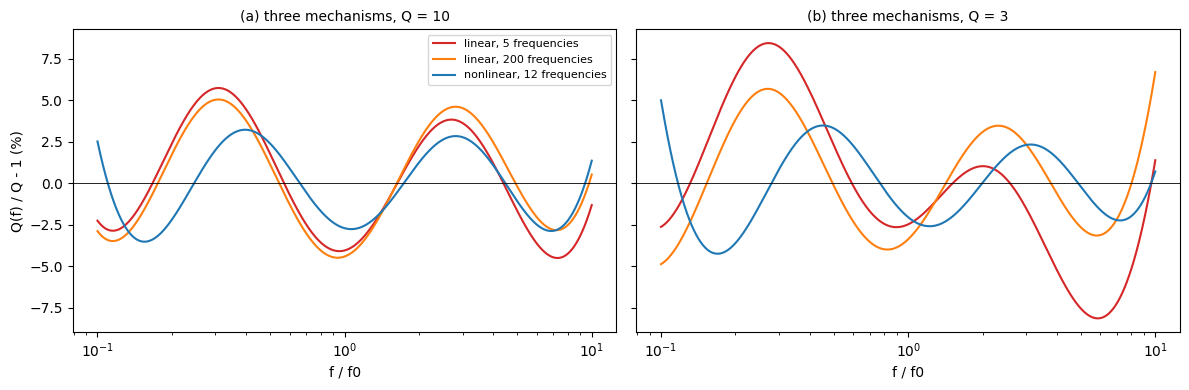

largest |Q(f) / Q - 1| over the band
  n_sls 2, Q   30: linear, 3 frequencies 134.2%   linear, 200 frequencies  90.8%   nonlinear, 8 frequencies  19.0%
  n_sls 2, Q   10: linear, 3 frequencies 138.7%   linear, 200 frequencies  95.9%   nonlinear, 8 frequencies  22.9%
  n_sls 2, Q    3: linear, 3 frequencies 157.0%   linear, 200 frequencies 196.5%   nonlinear, 8 frequencies  51.3%
  n_sls 3, Q   30: linear, 5 frequencies   5.1%   linear, 200 frequencies   4.9%   nonlinear, 12 frequencies   3.3%
  n_sls 3, Q   10: linear, 5 frequencies   5.8%   linear, 200 frequencies   5.1%   nonlinear, 12 frequencies   3.5%
  n_sls 3, Q    3: linear, 5 frequencies   8.5%   linear, 200 frequencies   6.7%   nonlinear, 12 frequencies   5.0%


  n_sls 4, Q   30: linear, 7 frequencies   3.4%   linear, 200 frequencies   5.2%   nonlinear, 16 frequencies   0.7%
  n_sls 4, Q   10: linear, 7 frequencies   4.0%   linear, 200 frequencies   6.1%   nonlinear, 16 frequencies   0.8%
  n_sls 4, Q    3: linear, 7 frequencies   7.0%   linear, 200 frequencies  10.1%   nonlinear, 16 frequencies   1.0%


In [2]:
f = np.geomspace(*BAND, 2000)


def q_error(tau, w, Q):
    m = GSLSNonlinearFit.modulus_ratio(tau, w, f)
    return m.real / m.imag / Q - 1.0


def fits(n, Q):
    tau = gsls_relaxation_times(n, *BAND)
    out = {}
    for k in (2 * n - 1, 200):
        lin = GSLSFit(tau, *BAND, n_freq=k)
        out[f"linear, {k} frequencies"] = (tau, lin.tau_np(Q))
    out[f"nonlinear, {4 * n} frequencies"] = GSLSNonlinearFit(n, *BAND).params_np(Q)
    return out


fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, Q, letter in zip(ax, (10.0, 3.0), "ab"):
    for (lab, (tau, w)), c in zip(fits(3, Q).items(), ("C3", "C1", "C0")):
        a.semilogx(f / F0, 100 * q_error(tau, w, Q), color=c, label=lab)
    a.axhline(0.0, color="k", lw=0.6)
    a.set_title(f"({letter}) three mechanisms, Q = {Q:g}", fontsize=10)
    a.set_xlabel("f / f0")
ax[0].set_ylabel("Q(f) / Q - 1 (%)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("largest |Q(f) / Q - 1| over the band")
for n in (2, 3, 4):
    for Q in (30.0, 10.0, 3.0):
        row = {lab: np.abs(q_error(tau, w, Q)).max() for lab, (tau, w) in fits(n, Q).items()}
        print(f"  n_sls {n}, Q {Q:4g}: " + "   ".join(f"{lab} {100 * e:5.1f}%" for lab, e in row.items()))

With three mechanisms over the two decades the linear fit's error is 5-9% at SPECFEM2D's five
frequencies and 5-7% at 200 (the dense fit minimises the mean square, not the largest error),
the nonlinear fit's 3-5%; with four, 3-10% against 0.7-1.0%. Two mechanisms are too few for
the band either way. Below a Q of 1.5 to 1.8 the linear fit needs a negative strength and is
refused; the nonlinear fit keeps every strength positive down to `Q = 1`.

The relaxation frequencies `1 / (2 pi tau_l)` it places move up as Q falls:

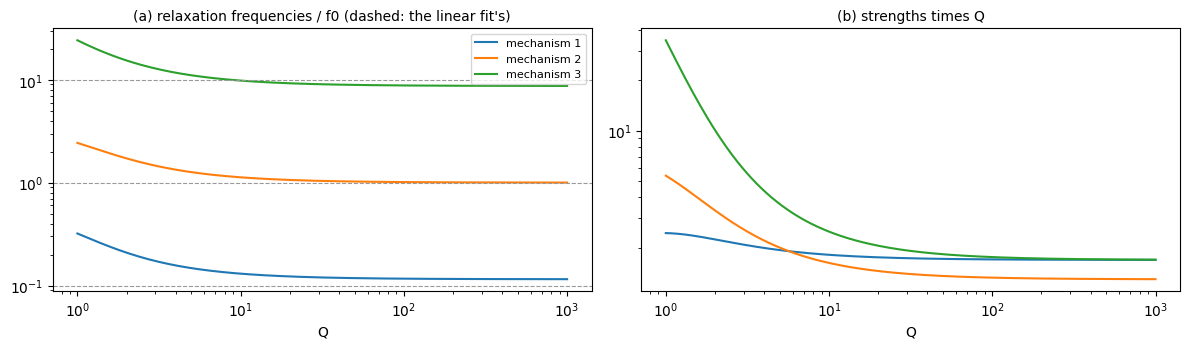

In [3]:
Qs = torch.logspace(0, 3, 200, dtype=torch.float64)
tau, w = GSLSNonlinearFit(3, *BAND).params(Qs)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for l in range(3):
    ax[0].loglog(Qs, 1.0 / (2 * np.pi * tau[l]) / F0, color=f"C{l}", label=f"mechanism {l + 1}")
    ax[1].loglog(Qs, w[l] * Qs, color=f"C{l}")
for fl in 1.0 / (2 * np.pi * gsls_relaxation_times(3, *BAND)) / F0:
    ax[0].axhline(fl, color="0.6", ls="--", lw=0.8)
ax[0].set_title("(a) relaxation frequencies / f0 (dashed: the linear fit's)", fontsize=10)
ax[1].set_title("(b) strengths times Q", fontsize=10)
for a in ax: a.set_xlabel("Q")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

Each node gets its own relaxation times, the bulk ones from `Qkappa` and the shear ones from
`Qmu`. The class maps the model's Q to them through a Chebyshev series in `1 / Q`, built once
per number of mechanisms, band ratio and number of frequencies (a fraction of a second), so Q
stays a differentiable model.

## 2. In a wave

An explosion in a homogeneous rock with `Qkappa = Qmu = 6` sends a P wave along a line of
receivers, with three and with four mechanisms. The ratio of the spectra at 150 m and 750 m from it, over the same ratio for the
elastic rock, is the attenuation and dispersion over those 600 m alone: the source and the
geometric spreading drop out. For a line source it is `H1(k r2) / H1(k r1)` over its elastic
value, with `k = w / c(w)` and `c(w) = sqrt(M(w) / rho)`, for the modulus each fit realises.
The velocities are read as SPECFEM2D's `READ_VELOCITIES_AT_f0` reads them
(`velocities="real_modulus"`), which anchors every modulus at 15 Hz. Against an exactly
constant Q -- `M(w) = M0 (i w / w0)^(2 gamma)`, `Q = 1 / tan(pi gamma)` -- the log of the
amplitude ratio over its constant-Q value, less one, is about the relative error of `1 / Q(f)`
the wave sees.

In [4]:
VP, VS, RHO, Q = 3000.0, 1500.0, 2400.0, 6.0
DH, NO, DT = 5.0, 4, 2.5e-4
NZ, NX = 161, 333                                 # 800 m x 1660 m, the C-PML outside
R1, R2 = 150.0, 750.0
NT = int(round(0.65 / DT))
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - 1.2 / F0)) ** 2
wav = torch.tensor((1.0 - 2.0 * a) * np.exp(-a), device=DEV)
src = np.array([[60.0, 80.0]])                    # x = 300 m, z = 400 m
rec = np.array([[[60.0 + R1 / DH, 80.0], [60.0 + R2 / DH, 80.0]]])


def shot(equation, **opts):
    p = PropSEM(equation, shape=(NZ, NX), dh=DH, dt=DT, n_order=NO, abcn=40, free_surface=False,
                f_dominant=F0, dev=DEV, impl="eager", dtype=torch.float64, source_type=["sxx", "szz"],
                receiver_type=["vx"], **({"equation_options": opts} if opts else {}))
    m = [torch.full((NZ, NX), v, dtype=torch.float64, device=DEV) for v in (VP, VS, RHO)]
    if opts:                                      # Qkappa and Qmu on the GLL nodes
        m += [torch.full(p._gll_shape, Q, dtype=torch.float64, device=DEV) for _ in range(2)]
    with torch.no_grad():
        return p(wav, src, rec, models=m)[0, :, :, 0].cpu().numpy()


t0 = time.time()
runs = {"elastic": shot(ElasticSEM2DDeformed)}
for n in (3, 4):
    opts = dict(f_ref=F0, n_sls=n, velocities="real_modulus")
    runs[n, "linear"] = shot(ViscoElasticSEM2DDeformed, **opts)
    runs[n, "nonlinear"] = shot(ViscoElasticSEM2DDeformed, fit="nonlinear", **opts)
print(f"five runs: {time.time() - t0:.0f} s")

sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 161x333 grid in float64; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


sweep: torch.compile is compiling the ViscoElasticSEM2DDeformed step for a 161x333 grid in float64


five runs: 33 s


3 mechanisms, linear    fit: attenuation against a constant Q -5.6 .. +4.0%; the SEM against its own modulus 7.1e-03
3 mechanisms, nonlinear fit: attenuation against a constant Q -3.8 .. +2.6%; the SEM against its own modulus 7.1e-03
4 mechanisms, linear    fit: attenuation against a constant Q -3.3 .. +3.3%; the SEM against its own modulus 6.5e-03
4 mechanisms, nonlinear fit: attenuation against a constant Q -0.9 .. +0.8%; the SEM against its own modulus 7.3e-03


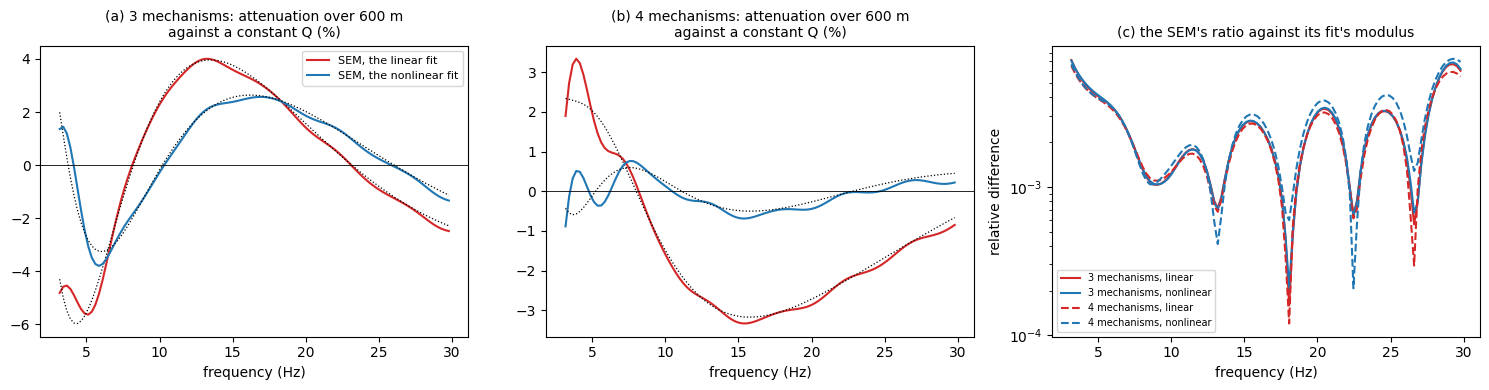

In [5]:
nf = 16384
fr = np.fft.rfftfreq(nf, DT)
spec = {k: np.fft.rfft(v, nf, axis=0) for k, v in runs.items()}
sel = (fr >= 3.0) & (fr <= 30.0)
fs, om = fr[sel], 2 * np.pi * fr[sel]
el = spec["elastic"][sel]
measured = {k: (v[sel, 1] / v[sel, 0]) / (el[:, 1] / el[:, 0]) for k, v in spec.items() if k != "elastic"}


def ratio(c):
    return (hankel2(1, om * R2 / c) / hankel2(1, om * R1 / c)) / \
           (hankel2(1, om * R2 / VP) / hankel2(1, om * R1 / VP))


def gsls_velocity(tau, w):
    m = GSLSNonlinearFit.modulus_ratio(tau, w, fs)
    m0 = GSLSNonlinearFit.modulus_ratio(tau, w, F0).real          # Re M(f0) = rho vp^2
    return VP * np.sqrt(m / m0)


gamma = np.arctan(1.0 / Q) / np.pi
target = ratio(VP * np.sqrt((1j * fs / F0) ** (2 * gamma) / np.cos(np.pi * gamma)))


def mechanisms(n, kind):
    if kind == "nonlinear":
        return GSLSNonlinearFit(n, *BAND).params_np(Q)
    tau = gsls_relaxation_times(n, *BAND)
    return tau, GSLSFit(tau, *BAND, n_freq=2 * n - 1).tau_np(Q)


deviation = lambda r: 100 * (np.log(np.abs(r)) / np.log(np.abs(target)) - 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for col, n in enumerate((3, 4)):
    for kind, c in (("linear", "C3"), ("nonlinear", "C0")):
        own = ratio(gsls_velocity(*mechanisms(n, kind)))
        got = measured[n, kind]
        ax[col].plot(fs, deviation(got), color=c, label=f"SEM, the {kind} fit")
        ax[col].plot(fs, deviation(own), "k:", lw=0.9)
        ax[2].semilogy(fs, np.abs(got / own - 1), color=c, ls="-" if n == 3 else "--",
                       label=f"{n} mechanisms, {kind}")
        print(f"{n} mechanisms, {kind:9s} fit: attenuation against a constant Q "
              f"{deviation(got).min():+.1f} .. {deviation(got).max():+.1f}%; the SEM against "
              f"its own modulus {np.abs(got / own - 1).max():.1e}")
    ax[col].axhline(0, color="k", lw=0.6)
    ax[col].set_title(f"({'ab'[col]}) {n} mechanisms: attenuation over 600 m\nagainst a constant Q (%)",
                      fontsize=10)
ax[2].set_title("(c) the SEM's ratio against its fit's modulus", fontsize=10)
ax[2].set_ylabel("relative difference")
for a_ in ax: a_.set_xlabel("frequency (Hz)")
ax[0].legend(fontsize=8); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

The SEM's ratio follows the modulus its fit realises (dotted) to a few 1e-3 (c), and that
modulus is what departs from the constant Q. With three mechanisms the attenuation over the
600 m strays from the constant Q's by -6 to +4% across 3-30 Hz with the linear fit and by -4
to +3% with the nonlinear one; with four, the nonlinear fit keeps it within about 1%.

## 3. The absorbing layer

A half-space with a free top, `Qkappa = 30`, `Qmu = 20` and the velocities read as unrelaxed
(SPECFEM2D's default), a vertical force 20 m deep, receivers 5 m deep: a 400 m x 800 m box with
a 10-element C-PML outside it against a box 1200 m larger to the left, right and below, from
whose edges nothing returns within the record. Their difference is the layer's reflection.
Before, the layer ran without attenuation -- here a model with `Q = inf` on the layer's elements
reproduces that -- so the modulus jumped at its edge.

In [6]:
NZ3, NX3, PAD, ABCN = 81, 161, 240, 40
NT3 = int(round(0.8 / DT))
t3 = np.arange(NT3) * DT
a3 = (np.pi * F0 * (t3 - 1.2 / F0)) ** 2
wav3 = torch.tensor((1.0 - 2.0 * a3) * np.exp(-a3), device=DEV)
xr = np.arange(4.0, 157.0, 8.0)


def half_space(equation, nz, nx, x0, abcn, q=None, layer_elastic=False):
    p = PropSEM(equation, shape=(nz, nx), dh=DH, dt=DT, n_order=NO, abcn=abcn, free_surface=True,
                f_dominant=F0, dev=DEV, impl="eager", dtype=torch.float64, source_type=["vz"],
                receiver_type=["vz"], **({"equation_options": {"f_ref": F0}} if q else {}))
    m = [torch.full((nz, nx), v, dtype=torch.float64, device=DEV) for v in (VP, VS, RHO)]
    if q:
        qs = [torch.full(p._gll_shape, v, dtype=torch.float64, device=DEV) for v in q]
        if layer_elastic:          # Q = inf on the elements of the layer
            xe, ze = p.mesh.x_e.mean((1, 2)), p.mesh.z_e.mean((1, 2))
            lay = abcn * DH
            out = (xe < lay) | (xe > lay + (nx - 1) * DH) | (ze > (nz - 1) * DH)
            qs = [torch.where(out.view(-1, 1, 1).to(DEV), float("inf"), v) for v in qs]
        m += qs
    r = np.array([[[x + x0, 1.0] for x in xr]])
    with torch.no_grad():
        return p(wav3, np.array([[80.3 + x0, 4.0]]), r, models=m)[0, :, :, 0].cpu().numpy()


t0 = time.time()
ref_e = half_space(ElasticSEM2DDeformed, NZ3 + PAD, NX3 + 2 * PAD, PAD, 8)
ref_v = half_space(ViscoElasticSEM2DDeformed, NZ3 + PAD, NX3 + 2 * PAD, PAD, 8, q=(30.0, 20.0))
layer = {"(a) elastic rock, its C-PML": (half_space(ElasticSEM2DDeformed, NZ3, NX3, 0, ABCN), ref_e),
         "(b) Q 30 / 20, the layer elastic": (
             half_space(ViscoElasticSEM2DDeformed, NZ3, NX3, 0, ABCN, q=(30.0, 20.0),
                        layer_elastic=True), ref_v),
         "(c) Q 30 / 20, the layer attenuating": (
             half_space(ViscoElasticSEM2DDeformed, NZ3, NX3, 0, ABCN, q=(30.0, 20.0)), ref_v)}
print(f"five runs: {time.time() - t0:.0f} s")

sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 321x641 grid in float64


sweep: torch.compile is compiling the ViscoElasticSEM2DDeformed step for a 321x641 grid in float64


sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 81x161 grid in float64


sweep: torch.compile is compiling the ViscoElasticSEM2DDeformed step for a 81x161 grid in float64


five runs: 23 s


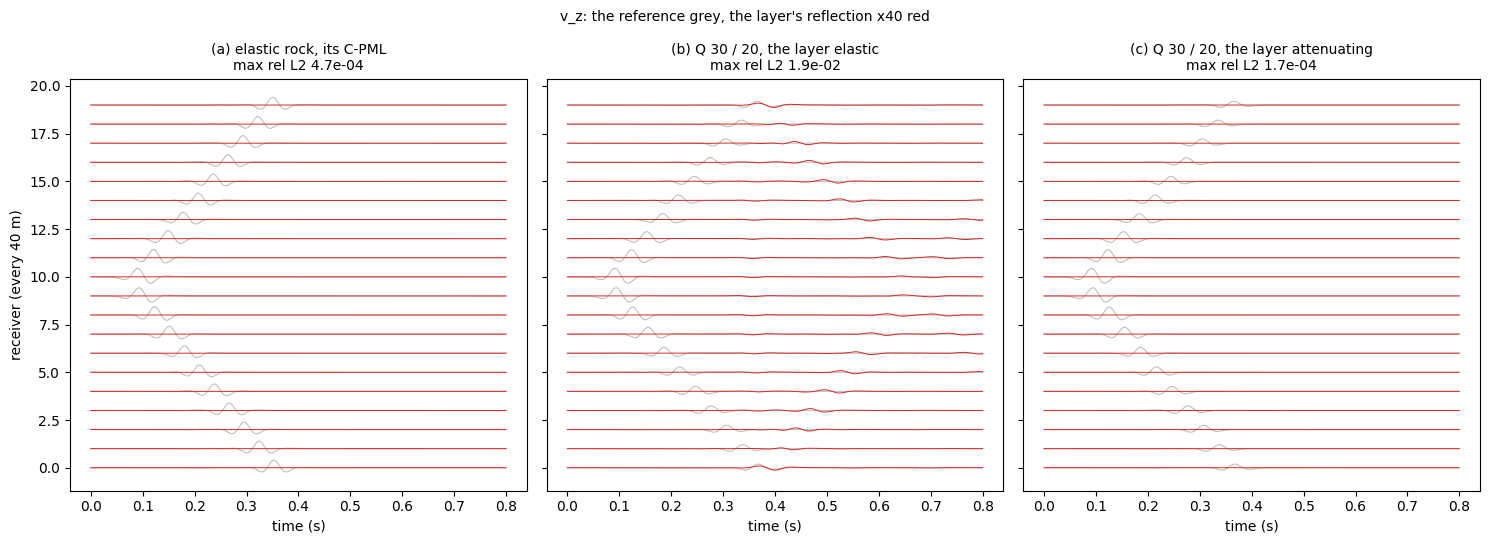

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
s = 0.45 / np.abs(ref_v).max()
for a_, (lab, (small, ref)) in zip(ax, layer.items()):
    err = np.linalg.norm(small - ref, axis=0) / np.linalg.norm(ref, axis=0)
    for i in range(len(xr)):
        a_.plot(t3, i + s * ref[:, i], color="0.75", lw=0.8)
        a_.plot(t3, i + 40 * s * (small[:, i] - ref[:, i]), color="C3", lw=0.7)
    a_.set_title(f"{lab}\nmax rel L2 {err.max():.1e}", fontsize=10)
    a_.set_xlabel("time (s)")
ax[0].set_ylabel("receiver (every 40 m)")
fig.suptitle("v_z: the reference grey, the layer's reflection x40 red", fontsize=10)
plt.tight_layout(); plt.show()

With the layer elastic (b) the reflection is tens of times the elastic rock's (a): the
waves of the band meet a stiffer medium at the layer's edge. With the layer attenuating (c) it
falls to the elastic level or below, as the attenuation also takes the little the C-PML
returns.

## 4. Notes

- **Where.** `fit="nonlinear"` on `ViscoElasticSEM2DDeformed` and `ViscoAcousticPotentialSEM2D`
  (`equation_options`; `n_fit=None` takes SPECFEM2D's `4 n_sls` frequencies, the displacement
  class's default). The velocity-stress classes keep one set of relaxation times for P and S
  and take no `fit`. All run on `impl='eager'`.
- **SPECFEM2D.** Its SolvOpt stops at about four significant digits; the mechanisms here agree
  with its own to 2.5e-4, at a residual a little lower, and the records of a run with
  `USE_SOLVOPT` to 2e-5 (6e-14 with its own mechanisms fed in). It fits every GLL point anew;
  the table here is built once. The attenuating layer agrees with SPECFEM2D's visco-elastic
  C-PML to 2.5e-7, and reflects as little.
- **Q.** Down to 1 with the nonlinear fit, 1.5 to 1.8 with the linear one. Read as unrelaxed
  (the default), `vp` and `vs` are the speeds the explicit step runs at; read at `f_ref`, the
  step runs at the unrelaxed velocities above them -- the built equation's `vp_e` and `vs_e`
  -- which a low Q raises: take `dt` from those.

---

<p><strong>Download this notebook</strong> &mdash; <a href="49_sem_attenuation.ipynb" download><code>49_sem_attenuation.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/49_sem_attenuation.ipynb">view on GitHub</a></p>